/tmp/ipykernel_165370/4224950588.py:25: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  normalization = np.trapz(posterior_unnormalized, x)
/tmp/ipykernel_165370/4224950588.py:43: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  l1_error = np.trapz(np.abs(posterior_numerical - posterior_analytical), x)


Posterior mu: 0.501451
Posterior sigma^2: 0.165541
Maximum absolute error: 3.31068506e-13
Integrated absolute error: 5.12984492e-13


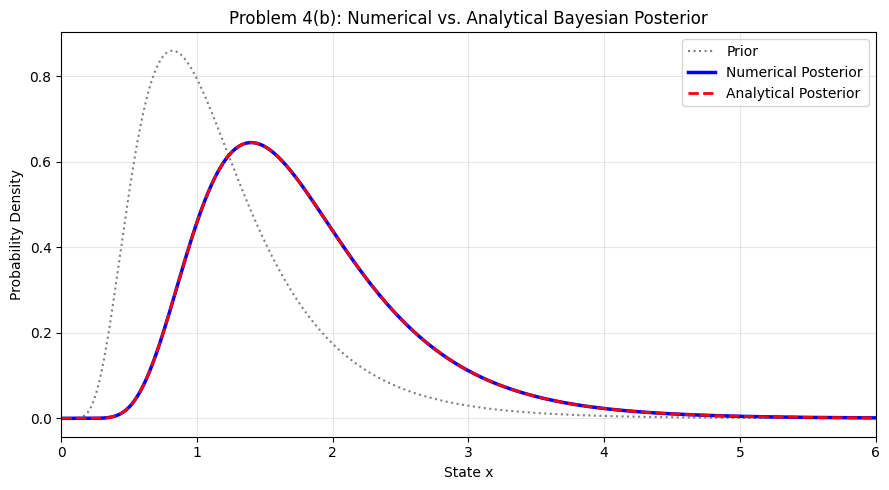

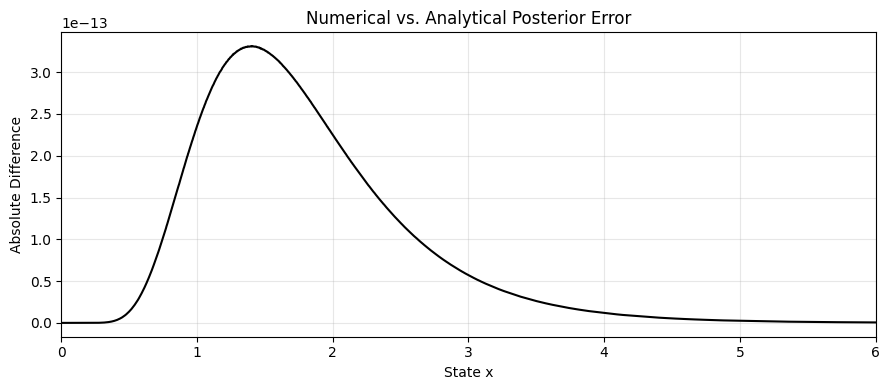

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Given parameters
mu_x = 0.05
sigma_x = 0.5
y = 4.0
sigma_y = 0.7

# Domain (lognormal distributions require x > 0)
x = np.linspace(0.001, 30, 10000)

# Equation (3): Prior distribution
prior = (1 / (x * sigma_x * np.sqrt(2 * np.pi))) * \
        np.exp(-(np.log(x) - mu_x)**2 / (2 * sigma_x**2))

# Equation (4): Likelihood
likelihood = (1 / (y * sigma_y * np.sqrt(2 * np.pi))) * \
             np.exp(-(np.log(y) - np.log(x))**2 / (2 * sigma_y**2))

# Numerical posterior using Bayes' theorem
posterior_unnormalized = prior * likelihood

# Normalize so the posterior integrates to 1
normalization = np.trapz(posterior_unnormalized, x)
posterior_numerical = posterior_unnormalized / normalization

# Equations (5) and (6): Analytical posterior parameters
mu_u = (mu_x * sigma_y**2 + np.log(y) * sigma_x**2) / \
       (sigma_x**2 + sigma_y**2)

sigma_u_sq = (sigma_x**2 * sigma_y**2) / \
             (sigma_x**2 + sigma_y**2)

sigma_u = np.sqrt(sigma_u_sq)

# Analytical lognormal posterior
posterior_analytical = (1 / (x * sigma_u * np.sqrt(2 * np.pi))) * \
                       np.exp(-(np.log(x) - mu_u)**2 / (2 * sigma_u_sq))

# Compare the two posterior distributions
max_error = np.max(np.abs(posterior_numerical - posterior_analytical))
l1_error = np.trapz(np.abs(posterior_numerical - posterior_analytical), x)

print(f"Posterior mu: {mu_u:.6f}")
print(f"Posterior sigma^2: {sigma_u_sq:.6f}")
print(f"Maximum absolute error: {max_error:.8e}")
print(f"Integrated absolute error: {l1_error:.8e}")

# Plot comparison
plt.figure(figsize=(9, 5))

plt.plot(x, prior, label="Prior", color="gray", linestyle=":")
plt.plot(x, posterior_numerical, label="Numerical Posterior",
         color="blue", linewidth=2.5)
plt.plot(x, posterior_analytical, label="Analytical Posterior",
         color="red", linestyle="--", linewidth=2)

plt.xlabel("State x")
plt.ylabel("Probability Density")
plt.title("Problem 4(b): Numerical vs. Analytical Bayesian Posterior")
plt.xlim(0, 6)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot numerical difference
plt.figure(figsize=(9, 4))

plt.plot(x, np.abs(posterior_numerical - posterior_analytical),
         color="black")
plt.xlabel("State x")
plt.ylabel("Absolute Difference")
plt.title("Numerical vs. Analytical Posterior Error")
plt.xlim(0, 6)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
